<a href="https://colab.research.google.com/github/zranadegirmenci/llm-metin-analizi-ve-structured-output/blob/main/llm_metin_analizi_ve_structured_output.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. API Bağlantısı, Prompt Tasarımı ve Yapılandırılmış Çıktı (JSON) Testi
Gemini API istemcisi başlatılmış, sistem promptu ile JSON şeması zorunlu tutulmuş ve tek bir serbest metin üzerinden yapılandırılmış veri üretimi doğrulanmıştır.

In [14]:
# Gerekli resmi Gemini kütüphanesini Colab ortamına kuruyoruz
!pip install -q -U google-genai

import os
import json
import pandas as pd
from google import genai
from google.genai import types

API_KEY = "YOUR_GEMINI_API_KEY_HERE"

client = genai.Client(api_key=API_KEY)
print("LLM API Bağlantısı Başarıyla Kuruldu!")

LLM API Bağlantısı Başarıyla Kuruldu!


In [15]:
# Analiz edilecek örnek serbest müşteri/hasta şikayet metinleri
ornek_metinler = [
    "Dün kardiyoloji randevum vardı, doktor çok ilgiliydi fakat sistem arızası yüzünden veznede 45 dakika beklemek zorunda kaldım. Sıram kaydı.",
    "Mobil uygulamanızdan randevu almaya çalışıyorum ama iki gündür ödeme adımında sürekli sunucu hatası verip kapanıyor! Acil ameliyat kontrolüm var!",
    "Tahlil sonuçlarımı sisteme yüklemişsiniz, teşekkürler. Yalnız rapor çıktısını PDF olarak indiremiyorum, buton çalışmıyor.",
    "Hastanenin otoparkı çok pahalı ve güvenlik görevlisi son derece kaba davrandı. Bir daha asla gelmeyi düşünmüyorum."
]

# Modeli ve Prompt Talimatını Belirleme
sistem_talimati = """
Sen uzman bir Müşteri Deneyimi ve Operasyon Analistisin.
Sana verilen kullanıcı metnini analiz etmeli ve SADECE geçerli bir JSON objesi olarak çıktı üretmelisin.
JSON formatı tam olarak şu anahtarları içermelidir:
{
    "kategori": "Hizmet" veya "Teknik" veya "Fatura/Ödeme" veya "Personel",
    "duygu": "Pozitif" veya "Nötr" veya "Negatif",
    "aciliyet_derecesi": 1 ile 5 arasında tam sayı (5: Çok Acil),
    "yonetici_ozeti": "Sorunu ve durumu anlatan maksimum 10 kelimelik net özet"
}
Markdown veya fazladan açıklama yazma, yalnızca saf JSON döndür.
"""

# İlk metni test etmek için API'ye gönderiyoruz
metin_1 = ornek_metinler[0]

prompt = f"Analiz edilecek metin:\n\"\"\"{metin_1}\"\"\""

cevap = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=prompt,
    config=types.GenerateContentConfig(
        system_instruction=sistem_talimati,
        response_mime_type="application/json" # Modele zorla JSON ürettiren ayar
    )
)

print("--- Orijinal Metin ---")
print(metin_1)

print("\n--- Modelin Ürettiği Yapılandırılmış Çıktı (JSON) ---")
print(cevap.text)

--- Orijinal Metin ---
Dün kardiyoloji randevum vardı, doktor çok ilgiliydi fakat sistem arızası yüzünden veznede 45 dakika beklemek zorunda kaldım. Sıram kaydı.

--- Modelin Ürettiği Yapılandırılmış Çıktı (JSON) ---
{
    "kategori": "Teknik",
    "duygu": "Negatif",
    "aciliyet_derecesi": 3,
    "yonetici_ozeti": "Sistem arızası nedeniyle veznede 45 dakika bekleme ve sıra kaybı."
}


# 2. Çoklu Metinlerin Otomatik Analizi ve Yapılandırılmış Veri Tablosuna (DataFrame) Çevrilmesi
Serbest kullanıcı geri bildirimleri LLM üzerinden asenkron/sıralı olarak işlenmiş, üretilen JSON verileri birleştirilerek iş zekası analizine uygun bir Pandas tablosu haline getirilmiştir.

In [16]:
import time

analiz_sonuclari = []

print("Metinler analiz ediliyor, lütfen bekleyin...\n")

for i, metin in enumerate(ornek_metinler, 1):
    prompt = f"Analiz edilecek metin:\n\"\"\"{metin}\"\"\""

    # API çağrısı
    yanit = client.models.generate_content(
        model='gemini-3.8-flash',
        contents=prompt,
        config=types.GenerateContentConfig(
            system_instruction=sistem_talimati,
            response_mime_type="application/json"
        )
    )

    try:
        veri = json.loads(yanit.text)
        veri['orijinal_metin'] = metin
        analiz_sonuclari.append(veri)
        print(f"[{i}/{len(ornek_metinler)}] Metin başarıyla analiz edildi.")
    except Exception as e:
        print(f"Hata oluştu: {e}")

    time.sleep(1) # API kotasını yormamak için kısa bir bekleme

# Sonuçları Pandas DataFrame'ine dönüştürme
df_llm = pd.DataFrame(analiz_sonuclari)

# Sütun sırasını düzenleme
df_llm = df_llm[['kategori', 'duygu', 'aciliyet_derecesi', 'yonetici_ozeti', 'orijinal_metin']]

print("\n--- LLM Tarafından Yapılandırılmış Analiz Tablosu ---")
df_llm

Metinler analiz ediliyor, lütfen bekleyin...

[1/4] Metin başarıyla analiz edildi.
[2/4] Metin başarıyla analiz edildi.
[3/4] Metin başarıyla analiz edildi.
[4/4] Metin başarıyla analiz edildi.

--- LLM Tarafından Yapılandırılmış Analiz Tablosu ---


,kategori,duygu,aciliyet_derecesi,yonetici_ozeti,orijinal_metin
0,Teknik,Negatif,3,Sistem arızası sebebiyle veznede 45 dakika bek...,"Dün kardiyoloji randevum vardı, doktor çok ilg..."
1,Teknik,Negatif,5,"Uygulama ödemede çöküyor, acil ameliyat kontro...",Mobil uygulamanızdan randevu almaya çalışıyoru...
2,Teknik,Nötr,3,Tahlil raporu PDF indirme butonu çalışmıyor.,"Tahlil sonuçlarımı sisteme yüklemişsiniz, teşe..."
3,Personel,Negatif,3,Pahalı otopark ve kaba güvenlik personeli nede...,Hastanenin otoparkı çok pahalı ve güvenlik gör...


# 3. Müşteri Geri Bildirim Dağılımı ve Aciliyet Seviyesi Görselleştirmesi
Kategorilere göre ortalama aciliyet puanları ve duygu durumu dağılımı görselleştirilmiş, operasyonel müdahale bekleyen kritik bildirimler filtrelenmiştir.

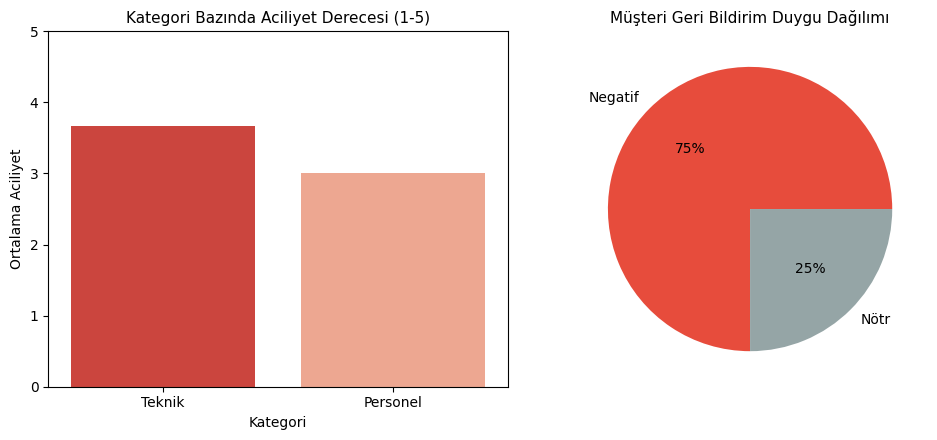

--- ACİL MÜDAHALE BEKLEYEN GERİ BİLDİRİMLER (Aciliyet >= 4) ---


,kategori,aciliyet_derecesi,yonetici_ozeti
1,Teknik,5,"Uygulama ödemede çöküyor, acil ameliyat kontro..."


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4.5))

# 1. Grafik: Kategoriye Göre Aciliyet Puanları
plt.subplot(1, 2, 1)
sns.barplot(
    data=df_llm,
    x='kategori',
    y='aciliyet_derecesi',
    hue='kategori',
    palette='Reds_r',
    errorbar=None,
    legend=False
)
plt.title('Kategori Bazında Aciliyet Derecesi (1-5)', fontsize=11)
plt.xlabel('Kategori')
plt.ylabel('Ortalama Aciliyet')
plt.ylim(0, 5)

# 2. Grafik: Duygu Durum Dağılımı
plt.subplot(1, 2, 2)
df_llm['duygu'].value_counts().plot(kind='pie', autopct='%1.0f%%', colors=['#e74c3c', '#95a5a6', '#2ecc71'])
plt.title('Müşteri Geri Bildirim Duygu Dağılımı', fontsize=11)
plt.ylabel('')

plt.tight_layout()
plt.show()

# En Acil Müdahale Edilmesi Gereken Kayıtlar (İş Zekası Filtresi)
print("--- ACİL MÜDAHALE BEKLEYEN GERİ BİLDİRİMLER (Aciliyet >= 4) ---")
df_acil = df_llm[df_llm['aciliyet_derecesi'] >= 4][['kategori', 'aciliyet_derecesi', 'yonetici_ozeti']]
df_acil

# 4. Operasyonel Aksiyon Matrisi ve Kök Neden Analitiği (Root Cause & Action Matrix)
Yapılandırılmış veriler üzerinden departman yöneticileri için önceliklendirilmiş aksiyon planı ve SLA (Hizmet Seviyesi Anlaşması) risk tablosu modellenmiştir.

In [18]:
# Departman bazlı risk ve öncelik agregasyonu
aksiyon_matrisi = df_llm.groupby('kategori').agg(
    Toplam_Bildirim=('orijinal_metin', 'count'),
    Ortalama_Aciliyet=('aciliyet_derecesi', 'mean'),
    Negatif_Orani=('duygu', lambda x: (x == 'Negatif').mean() * 100)
).reset_index()

# Öncelik Derecesi Belirleme Kuralı
def oncelik_belirle(row):
    if row['Ortalama_Aciliyet'] >= 4 or row['Negatif_Orani'] >= 80:
        return '🔴 KRİTİK - Anlık Müdahale (SLA < 2 Saat)'
    elif row['Ortalama_Aciliyet'] >= 2.5:
        return '🟡 ORTA - Gün İçi İnceleme (SLA < 24 Saat)'
    else:
        return '🟢 STANDART - Rutin Takip'

aksiyon_matrisi['Operasyonel_Oncelik'] = aksiyon_matrisi.apply(oncelik_belirle, axis=1)
aksiyon_matrisi = aksiyon_matrisi.sort_values(by='Ortalama_Aciliyet', ascending=False)

print("--- DEPARTMAN ÖNCELİK VE AKSİYON MATRİSİ ---")
aksiyon_matrisi

--- DEPARTMAN ÖNCELİK VE AKSİYON MATRİSİ ---


,kategori,Toplam_Bildirim,Ortalama_Aciliyet,Negatif_Orani,Operasyonel_Oncelik
1,Teknik,3,3.666667,66.666667,🟡 ORTA - Gün İçi İnceleme (SLA < 24 Saat)
0,Personel,1,3.000000,100.000000,🔴 KRİTİK - Anlık Müdahale (SLA < 2 Saat)
